# Analyze a batch: per task and pooled

Reads `batch_summary.json` (written by `batch.py`). Question: is boundary-concentrated failure (H1) general, or specific to the pipeline task's module-split boundaries? Compare three task shapes: **pipeline** (boundaries = module/file splits joined by a schema), **calc** (one file; boundaries = capability groups joined by state), **refactor** (edit sites in existing code).

Signals, and how far to trust them:
- `global_ok`: hidden pytest suite, exit code only (`checker.py`). Independent.
- `local_self_report` / `local_all_ok`: the agent's own claims. **Untrusted.**
- `step_failed`: objective, from what the harness observed (rejected write, tool error, non-zero shell exit).
- `is_recovery_step`: a step after an objectively failed step in the same substep.

In [1]:
# OPTIONAL: run the batch from here (calls the API, costs money, takes a while).
# Same as `py -3.12 batch.py --n 20 --seed-base 1000`. Flip to True once, run, flip back.
RUN_BATCH = True

if RUN_BATCH:
    import batch, harness
    batch.run_batch(batch.load_tasks(), harness.AnthropicAgent(), n=20, seed_base=1000)

[1/60] pipeline seed=1000 end=plan_complete steps=40 global_ok=True local_all_ok=False
[2/60] pipeline seed=1001 end=plan_complete steps=29 global_ok=True local_all_ok=False
[3/60] pipeline seed=1002 end=plan_complete steps=31 global_ok=True local_all_ok=False
[4/60] pipeline seed=1003 end=plan_complete steps=29 global_ok=True local_all_ok=False
[5/60] pipeline seed=1004 end=plan_complete steps=27 global_ok=True local_all_ok=False
[6/60] pipeline seed=1005 end=plan_complete steps=26 global_ok=True local_all_ok=False
[7/60] pipeline seed=1006 end=plan_complete steps=31 global_ok=True local_all_ok=False
[8/60] pipeline seed=1007 end=plan_complete steps=29 global_ok=True local_all_ok=False
[9/60] pipeline seed=1008 end=plan_complete steps=34 global_ok=True local_all_ok=False
[10/60] pipeline seed=1009 end=plan_complete steps=36 global_ok=True local_all_ok=False
[11/60] pipeline seed=1010 end=plan_complete steps=42 global_ok=True local_all_ok=False
[12/60] pipeline seed=1011 end=plan_compl

In [2]:
import json, math
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

SUMMARY = Path("batch_summary.json")
if not SUMMARY.exists():
    raise SystemExit("batch_summary.json not found: no batch has been run yet. Set RUN_BATCH = True "
                     "in the cell above (or run `py -3.12 batch.py --n 20`), then re-run this notebook.")
S = json.load(open(SUMMARY, encoding="utf-8"))
runs = S["runs"]
for r in runs:                       # summaries from the older single-task batch.py
    r.setdefault("task_id", S.get("task_id", "?"))
    for i, s in enumerate(r["steps"]):
        s.setdefault("step_idx", i)
TASKS = S.get("task_ids") or sorted({r["task_id"] for r in runs})
GROUPS = TASKS + ["POOLED"]

def runs_of(g):  return [r for r in runs if g == "POOLED" or r["task_id"] == g]
def ok_runs(g):  return [r for r in runs_of(g) if r["end_reason"] != "error"]  # errored runs have no steps
def steps_of(g): return [s for r in ok_runs(g) for s in r["steps"]]

def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else float("nan")

def wilson(k, n, z=1.96):
    """95% Wilson interval for a rate k/n (sensible at small n and at 0 or 1)."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))

print(f"batch {S['batch_id']} | backend {S['backend']} | complete: {S.get('complete', '?')}")
for g in GROUPS:
    print(f"  {g:9} runs {len(runs_of(g)):>3}  errored {len(runs_of(g)) - len(ok_runs(g)):>2}  "
          f"steps {len(steps_of(g)):>5}")
if not S.get("complete", True):
    print("\nWARNING: the batch did not finish; these are the runs completed so far.")
n_per = Counter(r["task_id"] for r in runs)
print(f"\nCAVEAT: n={min(n_per.values())}-{max(n_per.values())} runs per task, {len(TASKS)} tasks, ONE model; "
      "this shows within-task failure location for these tasks, not a general claim about agents.")

batch batch20261011_131609 | backend anthropic:claude-haiku-5-5 | complete: True
  pipeline  runs  20  errored  0  steps   625
  calc      runs  20  errored  0  steps   789
  refactor  runs  20  errored  0  steps   482
  POOLED    runs  60  errored  0  steps  1896

CAVEAT: n=20-20 runs per task, 3 tasks, ONE model; this shows within-task failure location for these tasks, not a general claim about agents.


## 1. Outcomes per task

In [3]:
for g in GROUPS:
    rs, oks = runs_of(g), ok_runs(g)
    cell = Counter((r["local_all_ok"], r["global_ok"]) for r in oks)
    print(f"== {g}: global_ok {dict(Counter(r['global_ok'] for r in rs))}   "
          f"end_reason {dict(Counter(r['end_reason'] for r in rs))}")
    print(f"   {'':12}{'global PASS':>12}{'global FAIL':>12}   (errored runs excluded; local = UNTRUSTED)")
    for loc in (True, False):
        print(f"   {'local ' + ('PASS' if loc else 'FAIL'):12}{cell[(loc, True)]:>12}{cell[(loc, False)]:>12}")
    nv = sum(v for (loc, glob), v in cell.items() if glob is None)
    if nv:
        print(f"   (+ {nv} runs where the checker itself crashed: not in the table)")

lpgf = [r for r in ok_runs("POOLED") if r["local_all_ok"] is True and r["global_ok"] is False]
print(f"\n>>> LOCAL-PASS / GLOBAL-FAIL runs: {len(lpgf)}")
for r in lpgf:
    print(f"    {r['task_id']:9} run {r['run']:>2}  seed {r['seed']}  steps {r['n_steps']:>3}  -> {r['raw_json']}")

== pipeline: global_ok {True: 20}   end_reason {'plan_complete': 20}
                global PASS global FAIL   (errored runs excluded; local = UNTRUSTED)
   local PASS             0           0
   local FAIL            20           0
== calc: global_ok {True: 19, False: 1}   end_reason {'plan_complete': 18, 'no_tool_call': 1, 'max_steps': 1}
                global PASS global FAIL   (errored runs excluded; local = UNTRUSTED)
   local PASS             1           0
   local FAIL            18           1
== refactor: global_ok {True: 20}   end_reason {'plan_complete': 20}
                global PASS global FAIL   (errored runs excluded; local = UNTRUSTED)
   local PASS             5           0
   local FAIL            15           0
== POOLED: global_ok {True: 59, False: 1}   end_reason {'plan_complete': 58, 'no_tool_call': 1, 'max_steps': 1}
                global PASS global FAIL   (errored runs excluded; local = UNTRUSTED)
   local PASS             6           0
   local FAIL       

## 2. Failure rate by tag, per task (the H1 table)

Rate = failures / steps that EXIST with that tag (raw counts mislead: internal steps far outnumber boundary steps). Brackets = 95% Wilson interval. `B/I` = boundary rate / internal rate (>1 means failures concentrate at boundaries). Self-reported: a step with no report (run ended first) is in the denominator but not counted as a failure; `unrep` shows how many.

In [7]:
TAGS = ("boundary", "internal")
rates = {}   # rates[(group, tag, kind)] = (rate, lo, hi)

def fmt(r, lo, hi):
    return f"{r:6.3f} [{lo:.2f},{hi:.2f}]" if r == r else f"{'n/a':>6} {'':11}"

for kind, label in (("obj", "OBJECTIVE (step_failed)"), ("self", "SELF-REPORTED False (UNTRUSTED)")):
    print(label)
    print(f"{'task':9}{'B steps':>8}{'I steps':>8}   {'boundary rate':>21}   {'internal rate':>21}{'B/I':>7}"
          + (f"{'unrep B/I':>12}" if kind == "self" else ""))
    for g in GROUPS:
        st = steps_of(g)
        counts = []
        for t in TAGS:
            ts = [s for s in st if s["tag"] == t]
            k = sum(s["step_failed"] for s in ts) if kind == "obj" else sum(s["local_self_report"] is False for s in ts)
            rates[(g, t, kind)] = (k / len(ts) if ts else float("nan"), *wilson(k, len(ts)))
            counts.append(len(ts))
        rb, ri = rates[(g, "boundary", kind)][0], rates[(g, "internal", kind)][0]
        ratio = rb / ri if ri and ri == ri and rb == rb else float("nan")
        line = (f"{g:9}{counts[0]:>8}{counts[1]:>8}   {fmt(*rates[(g, 'boundary', kind)]):>21}   "
                f"{fmt(*rates[(g, 'internal', kind)]):>21}{ratio:>7.2f}")
        if kind == "self":
            unrep = [sum(s["local_self_report"] is None for s in st if s["tag"] == t) for t in TAGS]
            line += f"{unrep[0]:>6}/{unrep[1]:<5}"
        print(line)
    print()
print("Read the intervals before the point estimates: overlapping intervals mean the data "
      "do not separate boundary from internal for that task.")

OBJECTIVE (step_failed)
task      B steps I steps           boundary rate           internal rate    B/I
pipeline      105     520       0.019 [0.01,0.07]       0.042 [0.03,0.06]   0.45
calc          132     657       0.000 [0.00,0.03]       0.050 [0.04,0.07]   0.00
refactor      124     358       0.081 [0.04,0.14]       0.073 [0.05,0.10]   1.11
POOLED        361    1535       0.033 [0.02,0.06]       0.053 [0.04,0.07]   0.63

SELF-REPORTED False (UNTRUSTED)
task      B steps I steps           boundary rate           internal rate    B/I   unrep B/I
pipeline      105     520       0.019 [0.01,0.07]       0.056 [0.04,0.08]   0.34     0/4    
calc          132     657       0.015 [0.00,0.05]       0.053 [0.04,0.07]   0.28     1/17   
refactor      124     358       0.089 [0.05,0.15]       0.045 [0.03,0.07]   1.98     0/1    
POOLED        361    1535       0.042 [0.03,0.07]       0.052 [0.04,0.06]   0.80     1/22   

Read the intervals before the point estimates: overlapping intervals mea

## 3. Tokens: recovery cost and context cost

`tokens_in` is the whole context sent on that call (everything so far + the new observation), so it grows with position in the run. Recovery steps tend to come later and look input-expensive partly for that reason; `tokens_out` is unaffected. Types overlap (a recovery step is also boundary or internal).

In [5]:
TYPES = {"boundary": lambda s: s["tag"] == "boundary",
         "internal": lambda s: s["tag"] == "internal",
         "recovery": lambda s: s["is_recovery_step"]}
print(f"{'task':9}{'type':10}{'steps':>7}{'mean in':>10}{'mean out':>10}")
for g in GROUPS:
    st = steps_of(g)
    for name, pred in TYPES.items():
        sel = [s for s in st if pred(s)]
        print(f"{g:9}{name:10}{len(sel):>7}{mean(s['tokens_in'] for s in sel):>10.0f}"
              f"{mean(s['tokens_out'] for s in sel):>10.0f}")
    rec = [s for s in st if s["is_recovery_step"]]
    step_tok = sum(s["tokens_in"] + s["tokens_out"] for s in st)
    step_out = sum(s["tokens_out"] for s in st)
    share = sum(s["tokens_in"] + s["tokens_out"] for s in rec) / step_tok if step_tok else float("nan")
    share_out = sum(s["tokens_out"] for s in rec) / step_out if step_out else float("nan")
    print(f"{'':9}recovery steps {len(rec)}/{len(st)}: {share:.1%} of step tokens, "
          f"{share_out:.1%} of step OUTPUT tokens")

task     type        steps   mean in  mean out
pipeline boundary      105     16398       253
pipeline internal      520     15774       467
pipeline recovery       30     13781       561
         recovery steps 30/625: 4.2% of step tokens, 6.3% of step OUTPUT tokens
calc     boundary      132     17487       829
calc     internal      657     22208       576
calc     recovery       63     33033       482
         recovery steps 63/789: 12.1% of step tokens, 6.2% of step OUTPUT tokens
refactor boundary      124     14278       983
refactor internal      358     15497       345
refactor recovery       31     21468       608
         recovery steps 31/482: 9.0% of step tokens, 7.7% of step OUTPUT tokens
POOLED   boundary      361     16068       714
POOLED   internal     1535     18463       485
POOLED   recovery      124     25484       533
         recovery steps 124/1896: 9.2% of step tokens, 6.6% of step OUTPUT tokens


In [6]:
# Context cost. Input = context (re)sent each call, incl. the new observation; output = new
# generation (incl. thinking). Totals include planning and finish_substep turns.
BUCKETS = [(0, 4), (5, 9), (10, 19), (20, 39), (40, 10**9)]
print("mean tokens_in by step position (step_idx within the run; n = steps in that bucket)")
print(f"{'task':9}" + "".join(f"{(f'{a}-{b}' if b < 10**9 else f'{a}+'):>14}" for a, b in BUCKETS))
for g in GROUPS:
    st = steps_of(g)
    row = []
    for a, b in BUCKETS:
        sel = [s["tokens_in"] for s in st if a <= s["step_idx"] <= b]
        row.append(f"{mean(sel):>8.0f} n={len(sel):<3}" if sel else f"{'-':>14}")
    print(f"{g:9}" + "".join(row))

print("\nshare of ALL tokens: context (input) vs new output")
for g in GROUPS:
    tin = sum(r["tokens_total"]["input"] for r in ok_runs(g))
    tout = sum(r["tokens_total"]["output"] for r in ok_runs(g))
    tot = tin + tout
    print(f"{g:9} input {tin / tot if tot else float('nan'):6.1%}   "
          f"output {tout / tot if tot else float('nan'):6.1%}   (total {tot:,} tokens)")

mean tokens_in by step position (step_idx within the run; n = steps in that bucket)
task                0-4           5-9         10-19         20-39           40+
pipeline     5106 n=100    9435 n=100   15906 n=200   23408 n=223   34612 n=2  
calc         5067 n=96     8056 n=95    14503 n=190   29537 n=328   40044 n=80 
refactor     5253 n=100   10326 n=100   18202 n=195   25418 n=87              -
POOLED       5143 n=296    9293 n=295   16215 n=585   26833 n=638   39912 n=82 

share of ALL tokens: context (input) vs new output
pipeline  input  98.0%   output   2.0%   (total 18,914,563 tokens)
calc      input  97.8%   output   2.2%   (total 28,357,377 tokens)
refactor  input  97.8%   output   2.2%   (total 16,185,086 tokens)
POOLED    input  97.9%   output   2.1%   (total 63,457,026 tokens)


## 4. Figure: failure rate by tag, one group per task

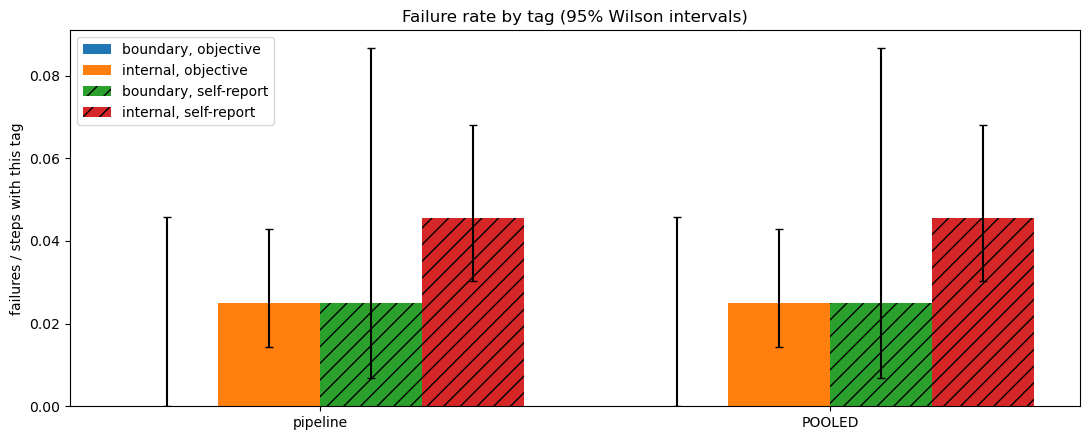

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
series = [("boundary", "obj", "boundary, objective"), ("internal", "obj", "internal, objective"),
          ("boundary", "self", "boundary, self-report"), ("internal", "self", "internal, self-report")]
w = 0.2
for j, (tag, kind, label) in enumerate(series):
    xs = [i + (j - 1.5) * w for i in range(len(GROUPS))]
    vals = [rates[(g, tag, kind)] for g in GROUPS]
    ys = [v[0] if v[0] == v[0] else 0 for v in vals]
    err = [[v[0] - v[1] if v[0] == v[0] else 0 for v in vals],
           [v[2] - v[0] if v[0] == v[0] else 0 for v in vals]]
    ax.bar(xs, ys, w, yerr=err, capsize=3, label=label, hatch="" if kind == "obj" else "//")
ax.set_xticks(range(len(GROUPS)), GROUPS)
ax.set_ylabel("failures / steps with this tag")
ax.set_title("Failure rate by tag (95% Wilson intervals)")
ax.legend()
fig.tight_layout()
plt.show()